# 7. 1D Grating with Three Inclusions: Compound Grating Resonances

## Physical Motivation & Learning Objectives
Compound gratings containing three sub-elements per period enable fine control over higher-order diffracted beams and phase profiles. In this tutorial:
1. We construct a 3-inclusion unit cell whose inclusion surfaces are equally spaced (`edge_spacing=True`).
2. We simulate compound diffraction spectra.


**Legacy example.** This notebook reproduces `simo_032-1D_grating-3_inclusions.py` from the original EMUstack. The `LEGACY_PARAMS` switch in the next cell selects the inputs:

- `LEGACY_PARAMS = True` *(default)*: the legacy inputs, unchanged. T, R and A then agree with legacy EMUstack to 1e-11 (checked in `benchmarks/parity/`, `examples/` version)
- `LEGACY_PARAMS = False`: 41 wavelengths instead of 2.

In [ ]:
# True: the inputs of the original EMUstack example, unchanged.
# False: same structure, 41 wavelengths instead of 2.
LEGACY_PARAMS = True

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## Grating Setup: Three Inclusions

$\Lambda = 300$ nm, height 2900 nm. The inclusions are 45, 81 and 9 nm wide, made of `inclusion_a` ($n = 5.0$) and `inclusion_b` ($n = 3.0$), in a background of $n = 1.46$.

In [2]:
wavelengths = np.linspace(400, 800, 2 if LEGACY_PARAMS else 41)
period = 300.0  # nm

light_list = [objects.Light(wl, max_order_PWs=5, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)

grating = objects.NanoStruct(
    '1D_array', period,
    diameter1=int(round(0.15 * period)),
    diameter2=int(round(0.27 * period)),
    diameter3=int(round(0.03 * period)),
    edge_spacing=True,
    height_nm=2900.0,
    background=materials.Material(1.46),
    inclusion_a=materials.Material(5.0),
    inclusion_b=materials.Material(3.0),
    loss=True, lc_bkg=0.0071, plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_grt = grating.calc_modes(light)
    stk = Stack((sim_sub, sim_grt, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor(max_workers=24) as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


## Compound Grating Spectra


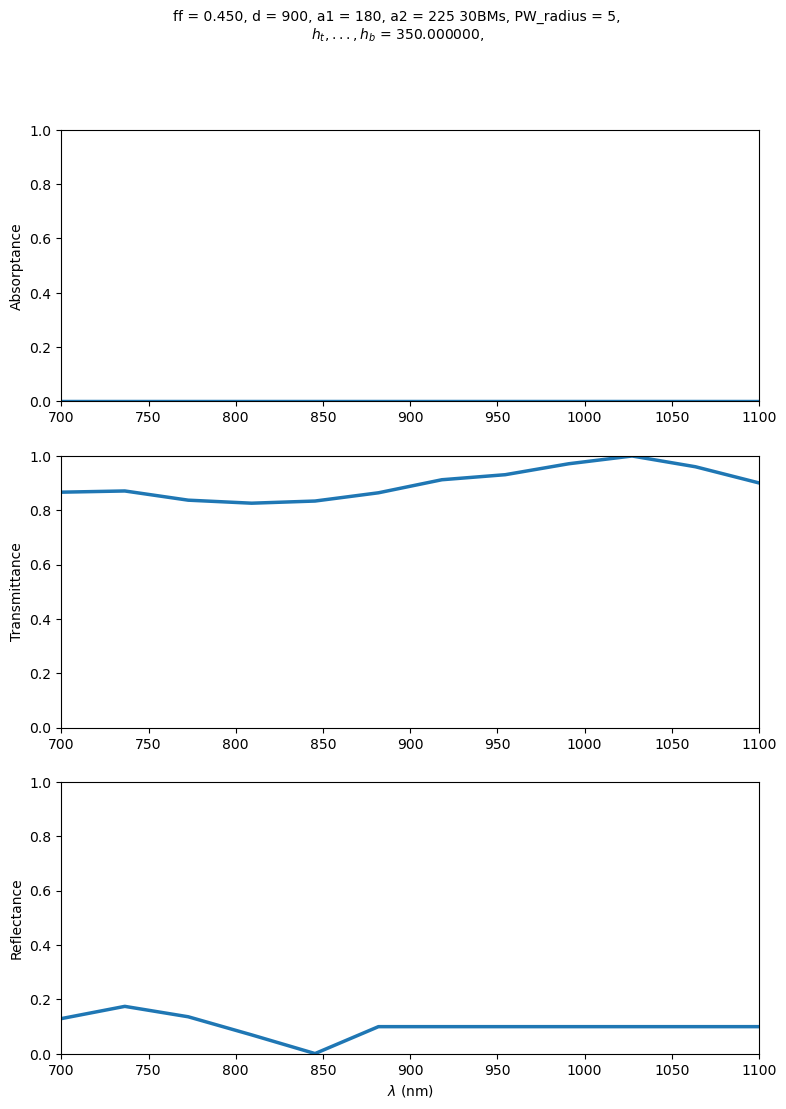

In [3]:
fig_tra = plotting.t_r_a_plots(stacks_list, save_pdf=False, save_txt=False)
plt.show()


## Physical Interpretation
- The structure is lossless, so $T + R = 1$.
- The spectrum oscillates rapidly for the same reason as in the previous two notebooks: many Bloch modes interfere inside a 2.9 µm-thick, high-index layer.
